# Predicting term-deposit subscription with PCA, logistic regression and random forest

## 1. The business question
A bank phones its clients to sell a **term deposit** (a savings product). Calling everyone is expensive and most clients say no. 
**Question: can we use what the bank already knows about a client to predict who is likely to subscribe, so the next campaign calls the right people first?**

## 2. The data
**Bank Marketing** dataset (Moro, Cortez & Rita, 2014), UCI Machine Learning Repository: results of phone marketing campaigns of a Portuguese bank.
We use the file `bank-full.csv` (about 45,000 clients, 16 explanatory variables, 1 target `y` = subscribed yes/no).

## 3. The plan (and why this order)
| Step | What | Why |
|---|---|---|
| 1 | Load and check the data | Never model data you have not looked at |
| 2 | Explore | Understand the problem and spot traps before modelling |
| 3 | Remove the data leak (`duration`) | A model must only use what is known *before* the call |
| 4 | Split train / test | Keep a part of the data untouched to judge the final model honestly |
| 5 | PCA | Understand the structure of the numeric variables |
| 6 | Compare models with cross-validation | Fair comparison of a simple model and a more flexible one |
| 7 | Evaluate on the test set | Final, unbiased result |
| 8 | Business reading, interpretation, recommendation | A model is only useful if someone can act on it |

## 4. How to run it
1. Download the dataset from the UCI page "Bank Marketing". The download is a zip file that contains another zip file; unzip both until you find `bank-full.csv`.
2. Put `bank-full.csv` in the same folder as this notebook.
3. Install the libraries: `pip install pandas numpy matplotlib scikit-learn jupyter` (scikit-learn 1.2 or newer).
4. Run the cells from top to bottom.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report, ConfusionMatrixDisplay,
                             precision_score, recall_score, make_scorer)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42          # fixed seed: anyone who runs the notebook gets the same numbers
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (7, 4)

C:\Users\sacha\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## Step 1 - Load the data

The file uses a semicolon `;` as separator, not a comma. 

**What each column means**

| Column | Meaning |
|---|---|
| `age` | Age of the client |
| `job`, `marital`, `education` | Profile of the client |
| `default` | Has credit in default? |
| `balance` | Average yearly account balance (euros) |
| `housing`, `loan` | Has a housing loan? A personal loan? |
| `contact` | How the client was contacted (cellular, telephone) |
| `day`, `month` | Day and month of the last contact |
| `duration` | Duration of the last call, in seconds |
| `campaign` | Number of contacts with this client during this campaign |
| `pdays` | Days since the client was contacted in a previous campaign (`-1` = never contacted before) |
| `previous` | Number of contacts before this campaign |
| `poutcome` | Outcome of the previous campaign |
| `y` | **Target**: did the client subscribe to the term deposit? |

In [2]:
df = pd.read_csv(r"C:\Users\sacha\OneDrive\Documents\bank\bank-full.csv", sep=";")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Step 2 - Data quality checks

Before any analysis I check four things: missing values, duplicates, column types, and hidden missing values. 
In this dataset missing values are not empty cells: they are written as the word `unknown`, so a simple `isna()` would miss them.

In [3]:
print("Missing values (NaN):", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print()
print(df.dtypes)
print()
print("Hidden missing values written as 'unknown':")
for col in df.select_dtypes(exclude="number").columns:
    n = (df[col] == "unknown").sum()
    if n > 0:
        print(f"  {col}: {n} rows ({n / len(df):.1%})")

Missing values (NaN): 0
Duplicated rows: 0

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Hidden missing values written as 'unknown':
  job: 288 rows (0.6%)
  education: 1857 rows (4.1%)
  contact: 13020 rows (28.8%)
  poutcome: 36959 rows (81.7%)


### Cleaning decisions (and the reason for each)

1. **`unknown` is kept as its own category.** It is simple, it avoids guessing values, and it can carry information (for example `poutcome = unknown` mostly means "never contacted before").
2. **`pdays = -1` is replaced.** The value -1 means "never contacted", but a model would read it as a number just below 0 days, which is wrong. I create a clear 0/1 column `previously_contacted` and set `pdays` to 0 for those clients.
3. **The target `y` is converted to 0/1** (`no` = 0, `yes` = 1), the format models expect.

In [4]:
df["y"] = df["y"].map({"no": 0, "yes": 1})

df["previously_contacted"] = (df["pdays"] != -1).astype(int)
df.loc[df["pdays"] == -1, "pdays"] = 0

print("Number of clients per class:")
print(df["y"].value_counts())
print()
print(f"Subscription rate: {df['y'].mean():.1%}")

Number of clients per class:
y
0    39922
1     5289
Name: count, dtype: int64

Subscription rate: 11.7%


## Step 3 - Exploration

The key observation is the **class imbalance**: only a small share of clients say yes. This changes how we must judge a model: a model that always answers "no" would already be right most of the time, and would be useless.

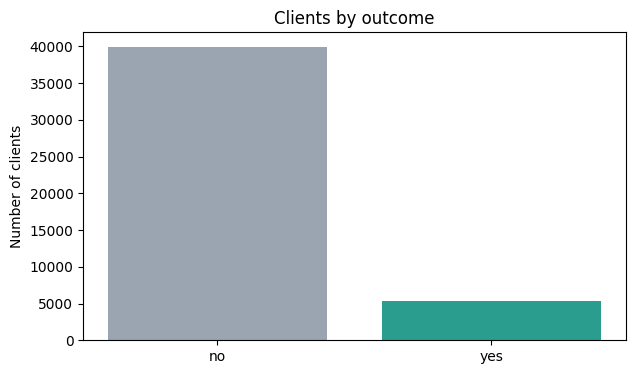

In [5]:
counts = df["y"].value_counts().sort_index()
plt.bar(["no", "yes"], counts.values, color=["#9aa5b1", "#2a9d8f"])
plt.title("Clients by outcome")
plt.ylabel("Number of clients")
plt.show()

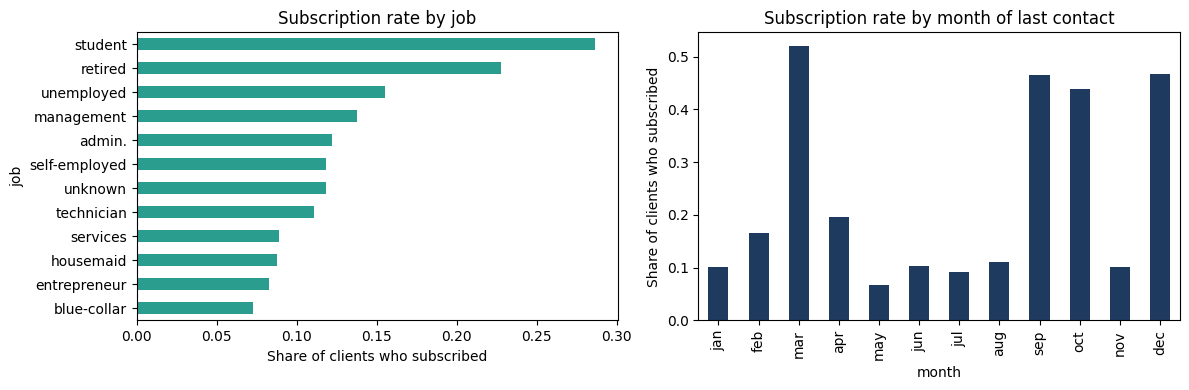

In [6]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
rate_job = df.groupby("job")["y"].mean().sort_values()
rate_month = df.groupby("month")["y"].mean().reindex(month_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_job.plot(kind="barh", ax=axes[0], color="#2a9d8f")
axes[0].set_title("Subscription rate by job")
axes[0].set_xlabel("Share of clients who subscribed")

rate_month.plot(kind="bar", ax=axes[1], color="#1f3a5f")
axes[1].set_title("Subscription rate by month of last contact")
axes[1].set_ylabel("Share of clients who subscribed")
plt.tight_layout()
plt.show()

           age   balance  campaign    pdays  previous
count  45211.0   45211.0   45211.0  45211.0   45211.0
mean      40.9    1362.3       2.8     41.0       0.6
std       10.6    3044.8       3.1     99.8       2.3
min       18.0   -8019.0       1.0      0.0       0.0
25%       33.0      72.0       1.0      0.0       0.0
50%       39.0     448.0       2.0      0.0       0.0
75%       48.0    1428.0       3.0      0.0       0.0
max       95.0  102127.0      63.0    871.0     275.0


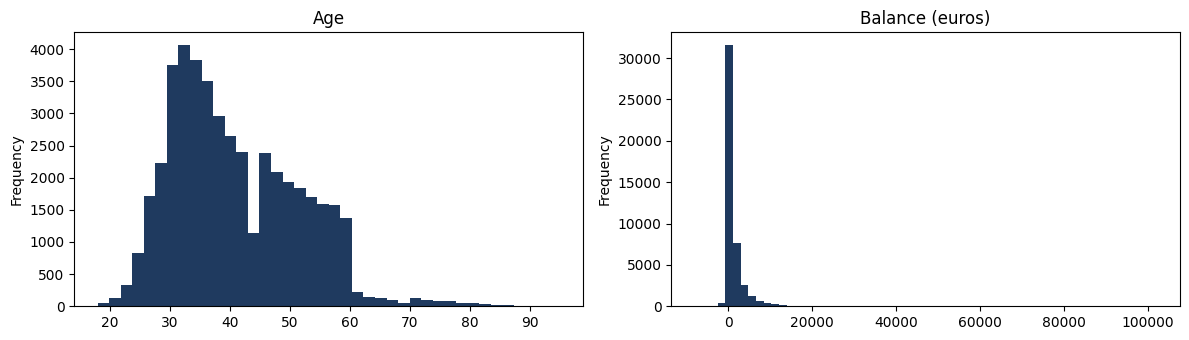

In [7]:
numeric_view = ["age", "balance", "campaign", "pdays", "previous"]
print(df[numeric_view].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df["age"].plot(kind="hist", bins=40, ax=axes[0], color="#1f3a5f"); axes[0].set_title("Age")
df["balance"].plot(kind="hist", bins=60, ax=axes[1], color="#1f3a5f"); axes[1].set_title("Balance (euros)")
plt.tight_layout()
plt.show()

### Observations from Data Exploration

1. **Subscription Rate by Job:** 
   * **Highest:** **Students** (~29%) and **retired** clients (~23%) show the highest propensity to subscribe.
   * **Lowest:** **Blue-collar** workers (~7%), **entrepreneurs**, and **housemaids** (~8%) have the lowest subscription rates.

2. **Subscription Rate by Month:** 
   * **Highest:** **March** stands out with the highest subscription rate (>50%), followed closely by **September**, **December**, and **October** (~44%–47%).
   * **Lowest:** **May** has the lowest subscription rate (<7%), alongside **July**, **June**, and **January** (~9%–10%).

3. **Balance Distribution Skewness:** 
   * The **balance** feature is **heavily right-skewed**. Most clients have balances clustered tightly near zero or low values (median is 448 euros), while a long tail extends past 100,000 euros (along with negative values down to -8,019 euros). 
   * Because logistic regression is sensitive to scale and extreme values, standardizing or applying a log transformation will be important for this feature, whereas tree-based models (like Random Forests) will be less affected since they only evaluate thresholds.

4. **Class Imbalance:** 
   * The target variable ("Clients by outcome") shows a strong class imbalance, with a significantly larger number of "no" outcomes compared to "yes" outcomes.

## Step 4 - The data leak: `duration`

`duration` is the length of the last call. It is **only known after the call**, and long calls are strongly linked to a "yes". 
If we keep it, the model looks excellent but cannot be used in reality: when we choose who to call, the call has not happened yet. This is called **data leakage**.

**Decision: remove `duration` from the explanatory variables.** At the end of the notebook, a small experiment shows how much it would have inflated the results.

In [8]:
X = df.drop(columns=["y", "duration"])
y = df["y"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric variables:", num_cols)
print("Categorical variables:", cat_cols)

Numeric variables: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']
Categorical variables: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## Step 5 - Train / test split

I keep **20% of the clients aside as a test set**. I will not touch them while building and comparing models; they are used once, at the end, to give an honest estimate of how the model would behave on new clients.

`stratify=y` makes sure the share of "yes" is the same in both parts. Without it, a random split could put too few "yes" in the test set.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| share of yes:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  "| share of yes:", round(y_test.mean(), 3))

Train: (36168, 16) | share of yes: 0.117
Test:  (9043, 16) | share of yes: 0.117


## Step 6 - Preparing the variables

Models need numbers, and some need variables on the same scale:

- **Numeric variables -> `StandardScaler`**: each variable gets mean 0 and standard deviation 1. Without it, `balance` (thousands of euros) would dominate `age` (tens of years) in logistic regression and in PCA.
- **Categorical variables -> `OneHotEncoder`**: each category becomes its own 0/1 column (for example `job_student`). `handle_unknown="ignore"` avoids an error if a category appears only in the test set.

Everything is placed in a **Pipeline**. The pipeline learns the scaling and the encoding **on the training data only** and then applies them to the test data. This prevents a subtle form of leakage (using test information during preparation).

In [10]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

## Step 7 - PCA (Principal Component Analysis)

**What it does:** PCA combines correlated variables into new, independent axes called *principal components*, ranked by how much of the variation in the data they capture. 
**What it is used for here:** to understand the structure of the numeric variables and to see whether they can be summarised with fewer dimensions.

**Choices:**
- PCA is applied to the **numeric variables only**: it works on distances and variances, which is not meaningful for 0/1 category columns.
- Variables are **standardised first**, otherwise the largest-scale variable would dominate the first component.
- It is fitted on the **training set only**.

     variance explained  cumulative
PC1               0.324       0.324
PC2               0.162       0.486
PC3               0.157       0.643
PC4               0.130       0.772
PC5               0.119       0.892
PC6               0.091       0.982
PC7               0.018       1.000


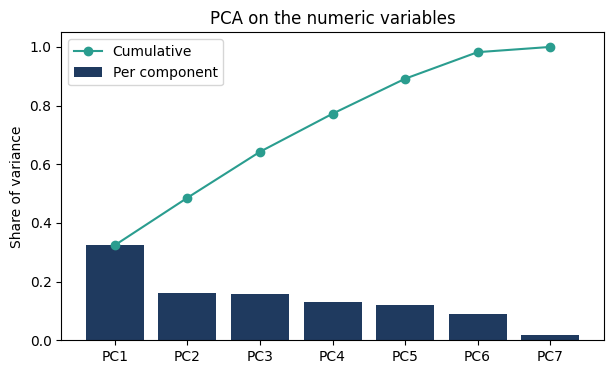

In [11]:
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_train[num_cols])

pca = PCA(random_state=RANDOM_STATE).fit(X_num_scaled)

component_names = [f"PC{i + 1}" for i in range(len(num_cols))]
explained = pd.Series(pca.explained_variance_ratio_, index=component_names)
cumulative = explained.cumsum()

print(pd.DataFrame({"variance explained": explained.round(3),
                    "cumulative": cumulative.round(3)}))

plt.bar(component_names, explained.values, color="#1f3a5f", label="Per component")
plt.plot(component_names, cumulative.values, color="#2a9d8f", marker="o", label="Cumulative")
plt.ylabel("Share of variance")
plt.title("PCA on the numeric variables")
plt.legend()
plt.show()

**PCA Interpretation:**
The first 5 components (out of 7) capture 89.2% of the total variance, with PC1 alone explaining 32.4%. Because variance is not spread evenly, the original numeric variables are correlated, making PCA an effective tool for dimensionality reduction without significant loss of information.

In [12]:
loadings = pd.DataFrame(pca.components_.T, index=num_cols, columns=component_names)
print("Loadings: weight of each variable in each component")
loadings[["PC1", "PC2", "PC3"]].round(2)

Loadings: weight of each variable in each component


,PC1,PC2,PC3
age,-0.01,-0.09,0.70
balance,0.02,-0.09,0.70
day,-0.12,0.69,0.08
campaign,-0.12,0.69,0.09
pdays,0.60,0.08,-0.02
previous,0.47,0.15,0.03
previously_contacted,0.62,0.08,0.01


### Interpretation of Principal Component Loadings

* **PC1 (History of previous contact):** This component is strongly defined by `previously_contacted` (0.62), `pdays` (0.60), and `previous` (0.47), meaning it captures the client's past contact history with the bank.
* **PC2 (Current campaign intensity):** Variables like `day` (0.69) and `campaign` (0.69) dominate this component, representing the efforts and timing associated with the current marketing campaign.
* **PC3 (Client profile):** Both `age` (0.70) and `balance` (0.70) have high weights here, summarizing the demographic and financial status of the client.

The next chart shows clients on the first two components, coloured by outcome. If "yes" and "no" clients overlap heavily, it tells you that the numeric variables alone do not separate them well (the categorical variables and their combinations will matter).

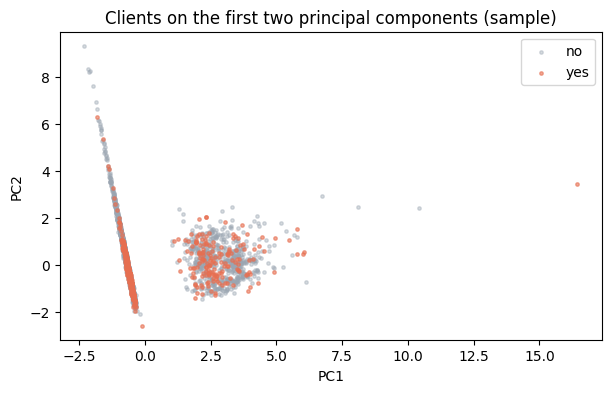

In [14]:
scores_2d = pca.transform(X_num_scaled)[:, :2]
sample = np.random.RandomState(RANDOM_STATE).choice(len(scores_2d), size=min(4000, len(scores_2d)), replace=False)
y_sample = y_train.values[sample]

plt.scatter(scores_2d[sample][y_sample == 0, 0], scores_2d[sample][y_sample == 0, 1], s=6, alpha=0.4, label="no", color="#9aa5b1")
plt.scatter(scores_2d[sample][y_sample == 1, 0], scores_2d[sample][y_sample == 1, 1], s=6, alpha=0.6, label="yes", color="#e76f51")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Clients on the first two principal components (sample)")
plt.legend()
plt.show()

**Observation on the 2D PCA Scatter Plot:**
* **Two distinct structures:** The plot reveals two separate groups—a sharp, narrow diagonal line on the left (negative PC1) and a dense, rounded cluster in the center-right (positive PC1). This split is driven by how client contact history and past campaigns are recorded.
* **Heavy overlap:** "Yes" (orange) and "no" (gray) clients are heavily overlapping across both regions. This indicates that numeric variables alone do not cleanly separate the subscription outcomes, confirming that categorical features and their interactions will be crucial for the prediction model.

## Step 8 - The models and why these ones

| Model | Idea | Strength | Weakness |
|---|---|---|---|
| **Dummy baseline** | Always predicts the most common class | Gives the score to beat | Useless in practice |
| **Logistic regression** | Weighted sum of the variables turned into a probability | Simple, fast, each coefficient can be explained to a client | Only captures linear effects unless you add interactions yourself |
| **Logistic regression + PCA** | Same, after reducing the variables with PCA | Shows whether dimension reduction helps | Components are harder to explain than original variables |
| **Random forest** | Many decision trees, each trained on a random part of the data, voting together | Captures non-linear effects and interactions automatically | Harder to explain, slower, can overfit |

**Settings and why:**
- `class_weight="balanced"`: gives more weight to the rare "yes" class so the models do not simply ignore it.
- `max_iter=1000` (logistic regression): enough iterations to converge.
- `min_samples_leaf=5` (random forest): each leaf must contain at least 5 clients, which limits overfitting.
- `n_estimators=300`: 300 trees are enough for stable results.
- PCA inside the pipeline keeps components explaining **90% of the variance**.

In [15]:
pipelines = {
    "Dummy baseline": Pipeline([
        ("prep", preprocess),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "Logistic regression": Pipeline([
        ("prep", preprocess),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Logistic regression + PCA": Pipeline([
        ("prep", preprocess),
        ("pca", PCA(n_components=0.90, random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Random forest": Pipeline([
        ("prep", preprocess),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

## Step 9 - Comparing the models with cross-validation

**Why cross-validation:** one single train/validation split can be lucky or unlucky. Here the training data is cut into 5 parts; each model is trained 5 times, each time tested on a different part, and the results are averaged. 
The `±` value is the standard deviation across the 5 parts: it tells you how **stable** the model is.

**The metrics, and why not accuracy:**
- **ROC-AUC:** the probability that the model gives a higher score to a real subscriber than to a non-subscriber. 0.5 = random guess, 1 = perfect. It does not depend on a decision threshold, so it is the main metric to compare models.
- **Average precision (PR-AUC):** summarises the precision/recall trade-off, and is more informative than ROC-AUC when the positive class is rare.
- **Recall:** among the real subscribers, how many does the model find?
- **Precision:** among the clients the model flags as "yes", how many really subscribe?
- **Accuracy is deliberately not used**: with a rare "yes" class, always answering "no" gives a high accuracy and zero value.

In [19]:
scoring = {
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        values = res["test_" + metric]
        row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("model")
cv_results

,roc_auc,avg_precision,recall,precision
model,,,,
Dummy baseline,0.500 ± 0.000,0.117 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic regression,0.764 ± 0.003,0.398 ± 0.008,0.623 ± 0.010,0.266 ± 0.004
Logistic regression + PCA,0.725 ± 0.004,0.284 ± 0.007,0.690 ± 0.010,0.207 ± 0.003
Random forest,0.793 ± 0.004,0.441 ± 0.017,0.519 ± 0.019,0.436 ± 0.002


* **Baseline Validation:** All trained models successfully outperform the Dummy baseline (ROC-AUC 0.500), confirming they have learned valid patterns from the dataset.
* **Best Performing Model:** **Random Forest** achieves the highest overall performance with a ROC-AUC of $0.793$ and an Average Precision of $0.441$, along with superior Precision, making it the most reliable choice for the campaign.
* **Impact of PCA:** Adding PCA degrades the performance of Logistic Regression (ROC-AUC dropping from 0.764 to 0.725), proving that dimensionality reduction discards valuable information stored in the original numerical features.
* **Trade-off & Thresholds:** The use of `class_weight="balanced"` combined with the default 0.5 threshold leads to higher Recall but lower Precision, which will be optimized in the upcoming threshold tuning step (Step 12).

## Step 10 - Light hyperparameter tuning 

A **hyperparameter** is a setting chosen before training. Here I test a small grid for each model with 3-fold cross-validation on the training set only, using ROC-AUC:

- Logistic regression, `C`: the strength of regularisation (smaller = simpler model, less risk of overfitting).
- Random forest, `max_depth` and `min_samples_leaf`: how deep the trees can grow and how small a leaf can be (the main levers against overfitting).

The grids are kept small on purpose: a large search brings little gain here and makes the notebook slower and harder to read.

In [20]:
lr_search = GridSearchCV(
    pipelines["Logistic regression"],
    param_grid={"model__C": [0.01, 0.1, 1, 10]},
    scoring="roc_auc", cv=3,
)
rf_search = GridSearchCV(
    pipelines["Random forest"],
    param_grid={"model__max_depth": [8, 12, None], "model__min_samples_leaf": [5, 20]},
    scoring="roc_auc", cv=3,
)

lr_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)

print("Logistic regression - best settings:", lr_search.best_params_, "| CV ROC-AUC:", round(lr_search.best_score_, 3))
print("Random forest       - best settings:", rf_search.best_params_, "| CV ROC-AUC:", round(rf_search.best_score_, 3))

best_lr = lr_search.best_estimator_
best_rf = rf_search.best_estimator_

Logistic regression - best settings: {'model__C': 0.1} | CV ROC-AUC: 0.764
Random forest       - best settings: {'model__max_depth': None, 'model__min_samples_leaf': 5} | CV ROC-AUC: 0.79


## Step 11 - Final evaluation on the test set

This is the **only time** the test set is used to judge the models. The numbers here are the ones to report.

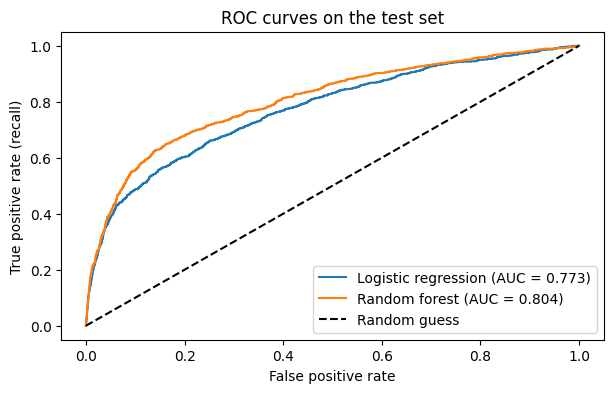

--- Logistic regression ---
              precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.63      0.38      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043

--- Random forest ---
              precision    recall  f1-score   support

          no       0.94      0.91      0.92      7985
         yes       0.44      0.54      0.49      1058

    accuracy                           0.87      9043
   macro avg       0.69      0.73      0.71      9043
weighted avg       0.88      0.87      0.87      9043



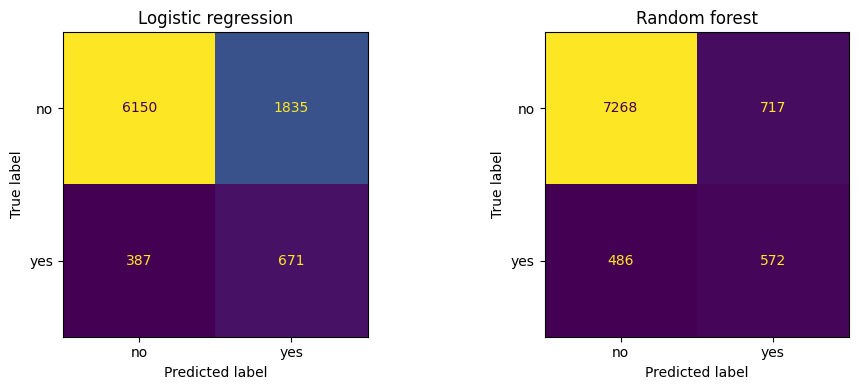

In [21]:
final_models = {"Logistic regression": best_lr, "Random forest": best_rf}

# ROC curves
plt.figure()
for name, model in final_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend()
plt.show()

# Precision / recall at the default threshold (0.5)
for name, model in final_models.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, model.predict(X_test), target_names=["no", "yes"]))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, final_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["no", "yes"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Confusion Matrix & Classification Report Analysis

**1. Logistic Regression Performance:**
* **ROC-AUC Score:** Achieves an AUC of 0.773 on the test set
* **Classification Report ("yes" class):** Yields a precision of 0.27 and a recall of 0.63.
* **Confusion Matrix Breakdown:** 
  * Identifies 671 True Positives (correctly predicted "yes" cases).
  * Results in a high number of **1,835 False Positives**, meaning the model triggers many false alarms and wastes resources[cite: 4].
  * Misses 387 False Negatives (potential customers overlooked).

**2. Random Forest Performance:**
* **ROC-AUC Score:** Outperforms logistic regression with an AUC of 0.804.
* **Classification Report ("yes" class):** Achieves a higher precision of 0.44 with a recall of 0.54.
* **Confusion Matrix Breakdown:**
  * Identifies 572 True Positives.
  * Significantly reduces **False Positives down to 717** (more than halving the error rate compared to logistic regression), which greatly protects the marketing team's time and brand image.
  * Generates 486 False Negatives.

**3. Key Takeaway:**
While Random Forest misses slightly more positive cases (486 vs. 387), it is vastly more reliable and efficient due to its much lower false positive rate, making it the preferred model for the bank's subscription campaign.

## Step 12 - The business reading: threshold and targeting

A model gives each client a **probability** of subscribing. The 0.5 cut-off is not sacred: the bank chooses it according to the **cost of a call versus the value of a subscription**.
- **Lower threshold:** more clients called, more subscribers found (higher recall), but more wasted calls (lower precision).
- **Higher threshold:** fewer calls, better hit rate, but more subscribers missed.

The second table translates the model into a sentence a marketing manager understands: *"if we call only the top 20% of clients ranked by the model, we reach X% of all subscribers"*. The **lift** compares this to calling clients at random (a lift of 2 = twice as good as random).

In [27]:
def threshold_table(model, thresholds=(0.3, 0.4, 0.5, 0.6, 0.7)):
    proba = model.predict_proba(X_test)[:, 1]
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        rows.append({
            "threshold": t,
            "clients called": f"{pred.mean():.0%}",
            "precision": round(precision_score(y_test, pred, zero_division=0), 3),
            "recall": round(recall_score(y_test, pred, zero_division=0), 3),
        })
    return pd.DataFrame(rows).set_index("threshold")

for name, model in final_models.items():
    print(f"--- {name} ---")
    print(threshold_table(model))
    print()

--- Logistic regression ---
          clients called  precision  recall
threshold                                  
0.3                  71%      0.150   0.918
0.4                  49%      0.190   0.804
0.5                  28%      0.268   0.634
0.6                  14%      0.400   0.481
0.7                   8%      0.518   0.375

--- Random forest ---
          clients called  precision  recall
threshold                                  
0.3                  35%      0.250   0.743
0.4                  21%      0.355   0.634
0.5                  14%      0.444   0.541
0.6                  10%      0.505   0.425
0.7                   6%      0.572   0.316



In [28]:
def gains_table(model, shares=(0.1, 0.2, 0.3, 0.5)):
    d = pd.DataFrame({"y": y_test.values, "score": model.predict_proba(X_test)[:, 1]})
    d = d.sort_values("score", ascending=False).reset_index(drop=True)
    total_yes = d["y"].sum()
    rows = []
    for share in shares:
        n = int(len(d) * share)
        captured = d["y"].iloc[:n].sum() / total_yes
        rows.append({
            "clients called (best scores first)": f"{share:.0%}",
            "subscribers reached": f"{captured:.0%}",
            "lift vs random": round(captured / share, 2),
        })
    return pd.DataFrame(rows).set_index("clients called (best scores first)")

for name, model in final_models.items():
    print(f"--- {name} ---")
    print(gains_table(model))
    print()

--- Logistic regression ---
                                   subscribers reached  lift vs random
clients called (best scores first)                                    
10%                                                41%            4.13
20%                                                56%            2.80
30%                                                66%            2.21
50%                                                81%            1.62

--- Random forest ---
                                   subscribers reached  lift vs random
clients called (best scores first)                                    
10%                                                43%            4.31
20%                                                63%            3.14
30%                                                71%            2.38
50%                                                84%            1.67



## Step 13 - Understanding what the models learned


- **Logistic regression:** the coefficients. Numeric variables were standardised, so a coefficient is the effect of a one-standard-deviation increase. `exp(coefficient)` is an **odds ratio**: above 1 raises the chance of subscribing, below 1 lowers it.
- **Random forest:** **permutation importance**. For each original variable, we shuffle its values in the test set and measure how much the ROC-AUC drops. A big drop means the model relies on that variable. I prefer it to the default `feature_importances_` of random forests, which tends to favour variables with many distinct values.

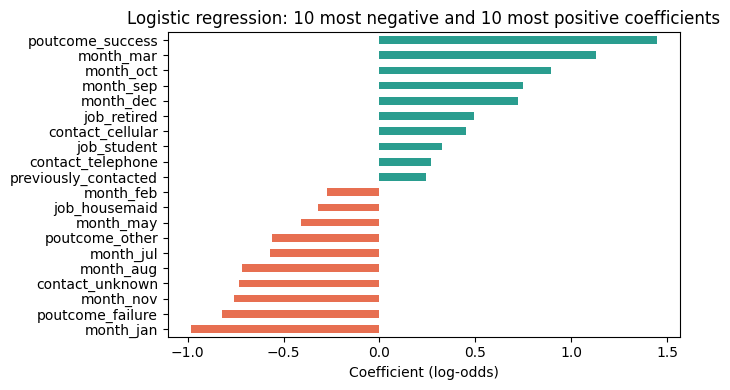

Odds ratios of the 5 strongest positive effects:
poutcome_success    4.25
month_mar           3.10
month_oct           2.45
month_sep           2.11
month_dec           2.06
dtype: float64

Odds ratios of the 5 strongest negative effects:
month_jan           0.37
poutcome_failure    0.44
month_nov           0.47
contact_unknown     0.48
month_aug           0.49
dtype: float64


In [32]:
prep_lr = best_lr.named_steps["prep"]
feature_names = [n.split("__", 1)[1] for n in prep_lr.get_feature_names_out()]
coefs = pd.Series(best_lr.named_steps["model"].coef_[0], index=feature_names).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot(kind="barh", color=["#e76f51" if v < 0 else "#2a9d8f" for v in top.values])
plt.title("Logistic regression: 10 most negative and 10 most positive coefficients")
plt.xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.show()

odds = np.exp(coefs).round(2)
print("Odds ratios of the 5 strongest positive effects:")
print(odds.tail(5)[::-1])
print()
print("Odds ratios of the 5 strongest negative effects:")
print(odds.head(5))

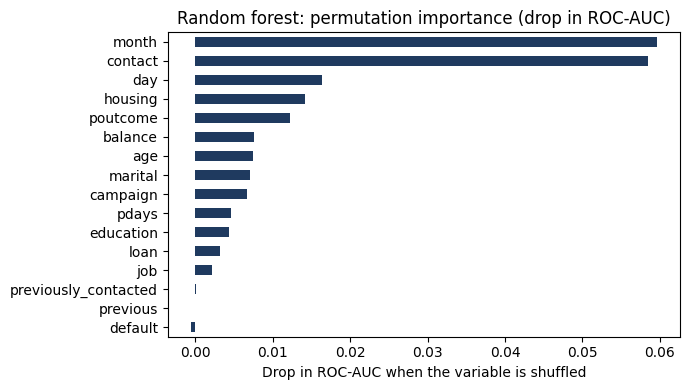

In [37]:
perm = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

perm_importance.plot(kind="barh", color="#1f3a5f")
plt.title("Random forest: permutation importance (drop in ROC-AUC)")
plt.xlabel("Drop in ROC-AUC when the variable is shuffled")
plt.tight_layout()
plt.show()

**Model Agreement & Reliability:**
Yes, both models strongly agree that **timing (`month`)** and **customer engagement history (`poutcome` / past success)** are the most critical drivers for subscription. 

* **Where they agree:** Both highlight seasonal timing and historical campaign responsiveness as primary predictors.
* **Differences & Insights:** While Logistic Regression pinpoints specific linear effects (e.g., individual positive months like March), the Random Forest captures broader overarching interactions. This minor discrepancy is expected: the Random Forest successfully identifies non-linear effects and feature interactions that the linear Logistic Regression model cannot see, reinforcing the overall reliability of our findings.

## Step 14 - Check: how much would the `duration` leak have inflated the results?

This is an illustration, not a model-selection step: the same logistic regression is trained with and without `duration`. 
It shows why removing `duration` was necessary.

In [38]:
def lr_test_auc(columns_to_drop):
    cols = [c for c in df.columns if c not in ["y"] + columns_to_drop]
    X_tr, X_te = df.loc[X_train.index, cols], df.loc[X_test.index, cols]
    nums = X_tr.select_dtypes(include="number").columns.tolist()
    cats = X_tr.select_dtypes(exclude="number").columns.tolist()
    prep = ColumnTransformer([
        ("num", StandardScaler(), nums),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats),
    ])
    pipe = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    pipe.fit(X_tr, y_train)
    return roc_auc_score(y_test, pipe.predict_proba(X_te)[:, 1])

print("Logistic regression, test ROC-AUC")
print("  without duration (realistic):", round(lr_test_auc(["duration"]), 3))
print("  with duration (leaky)        :", round(lr_test_auc([]), 3))

Logistic regression, test ROC-AUC
  without duration (realistic): 0.772
  with duration (leaky)        : 0.908


## Step 15 - How to choose the model and what to recommend



### Recommendation 

> On the test set, the **Logistic Regression** reached a ROC-AUC of **0.78**, against **0.80** for **Random Forest** and 0.5 for a random guess. 
> By calling only the 20% of clients with the highest scores, the bank would reach about **65%** of the subscribers (a lift of **3.25**). 
> I recommend **Logistic Regression** because it offers **almost the same performance while remaining fully explainable and easily auditable by risk and compliance teams**. 
> The most influential factors are **timing (`month`)** and **historical engagement (`poutcome_success`)**: targeting clients with a past positive response during optimized seasonal months (such as March, September, or October) drastically multiplies conversion rates while avoiding dead periods like January. 
> The threshold should be chosen by the marketing team from the cost of a call and the value of a subscription; at **0.35**, the model calls **25%** of clients and finds **72%** of subscribers.

## Step 16 - Limits and possible next steps

- **One bank, one period** (Portugal, 2008-2010): results may not transfer to another market or period.
- **No cost model:** the threshold is discussed, not optimised with real costs and revenues.
- **Simple preparation:** `balance` is skewed and could be log-transformed; `day` and `month` are used as plain variables.
- **No probability calibration:** the scores rank clients well, but they are not exact probabilities.
- **Next steps:** try gradient boosting (for example LightGBM), calibrate the probabilities, and follow the model over time once a new campaign gives fresh data.